In [21]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tqdm import tqdm

In [22]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [23]:
# HYPER PARAMETERS

batch_size = 128
num_epochs = 100
random_seed = 42
test_size = 0.05
learning_rate = 1e-3
total_features = 576

In [24]:
df_image = pd.read_csv('im_embeds_all300k.csv').drop(['Unnamed: 0'],axis=1)
df_likes = pd.read_excel('behaviour_simulation_train.xlsx')['likes']
#df_rest = pd.read_csv('Final_input_without_Img_embedding.csv')
df_comp = pd.read_csv('company_enc_red.csv')
df_text = pd.read_csv('text_enc_red.csv')
df_rest = pd.concat([df_comp,df_text,df_likes],axis=1)
print(df_rest.shape)
df_errors = pd.read_csv('im_embeds_errors_all300k.csv')
to_be_deleted = list(df_errors['0'])
df_rest.drop(to_be_deleted,inplace=True)
df_rest.reset_index(drop=True,inplace=True)
df_rest_temp = df_rest.dropna(axis=1, how='any')
df_rest_temp.shape

(300000, 65)


(295573, 65)

In [25]:
df_image.isna().sum().sum()

0

In [26]:
df_final = pd.concat([df_rest_temp,df_image],axis=1)
df_final

,0,1,2,3,4,5,6,7,8,9,...,502,503,504,505,506,507,508,509,510,511
0,-1.314151,4.765806,0.207886,-0.101585,-0.165719,-0.449897,-0.114058,-0.910192,1.197274,-0.005128,...,-0.296387,0.231689,-0.171997,0.044220,-0.131592,0.441895,0.123047,0.318604,-0.005260,-0.028809
1,4.865687,0.066496,-0.687646,-0.397136,-0.377484,-0.788848,0.005543,-0.243742,0.175889,-0.095510,...,0.138306,-0.169189,0.043549,0.015587,-0.220947,-0.436035,-0.275879,0.244141,-0.082642,0.199097
2,-0.668924,-1.182322,-1.626527,1.564492,-0.250642,-1.311279,0.299776,-1.308280,-2.155593,0.621701,...,0.376953,0.444092,-0.296387,-0.458252,-0.251709,-0.353760,0.401123,0.008011,-0.091980,0.050354
3,-0.221760,-1.531395,2.792290,1.305430,-1.201396,-0.895550,-0.448534,0.596436,0.609695,-0.487323,...,0.015266,-0.092834,-0.345947,-0.076782,-0.614746,-0.084290,-0.310059,0.819336,-0.333984,0.205688
4,4.865687,0.066496,-0.687646,-0.397136,-0.377484,-0.788848,0.005543,-0.243742,0.175889,-0.095510,...,-0.241211,0.214478,-0.356445,-0.498535,-0.416260,0.172729,0.078918,0.054016,-0.134277,0.002558
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295568,4.906795,0.816078,-0.175908,0.146349,-0.073756,0.137258,0.026600,-0.045405,0.089021,0.049508,...,0.284180,0.185791,-0.216797,0.378906,0.322510,0.132935,0.027740,0.480957,-0.399414,-0.461670
295569,-0.567468,-0.523874,-1.250610,1.926318,0.141228,-0.519172,0.327915,-1.054589,-2.172305,0.723622,...,-0.003538,-0.124695,0.557617,0.248169,0.341309,0.172729,-0.551270,-0.302490,0.114197,-0.663574
295570,-0.070691,-0.813510,3.101621,1.787546,-0.822979,-0.008647,-0.382195,0.862897,0.487195,-0.380364,...,0.129883,0.418701,-0.133301,-0.275146,-0.284912,0.099365,-0.489990,-0.013573,-0.043396,0.127441
295571,4.906795,0.816078,-0.175908,0.146349,-0.073756,0.137258,0.026600,-0.045405,0.089021,0.049508,...,-0.260498,0.113098,-0.755859,-0.347412,0.301025,0.044342,-0.117737,-0.496826,0.135498,0.154663


In [27]:
likes = df_final['likes']
likes

0            1
1         2750
2           57
3          152
4           41
          ... 
295568       0
295569      46
295570     261
295571     119
295572     714
Name: likes, Length: 295573, dtype: int64

In [28]:
max = likes.max()
min = likes.min()
print(max, min)

560193 0


In [29]:
# DATA LOADER

features = df_final.drop('likes', axis=1)
targets = df_final['likes']

train_features, val_features, train_targets, val_targets = train_test_split(
    features, targets, test_size=test_size, random_state=random_seed
)

class TabularDataset(Dataset):
    def __init__(self, features, targets):
        self.features = torch.tensor(features.values, dtype=torch.float32)
        self.targets = torch.tensor(targets.values, dtype=torch.float32)
        print(self.features.shape)
        print(self.targets.shape)

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return self.features[idx], self.targets[idx]

train_dataset = TabularDataset(train_features, train_targets)
val_dataset = TabularDataset(val_features, val_targets)

train_loader = DataLoader(train_dataset,
                          batch_size=batch_size,
                          shuffle=True)
val_loader = DataLoader(val_dataset,
                        batch_size=batch_size,
                        shuffle=False)

torch.Size([280794, 576])
torch.Size([280794])
torch.Size([14779, 576])
torch.Size([14779])


In [30]:
import torch.nn as nn

class Model(nn.Module):
    def __init__(self, total_features):
        super(Model, self).__init__()

        self.fc1 = nn.Linear(total_features, 1024)
        self.bn1 = nn.BatchNorm1d(1024)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.5)

        self.fc2 = nn.Linear(1024, 512)
        self.bn2 = nn.BatchNorm1d(512)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.5) 

        self.fc3 = nn.Linear(512, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.relu3 = nn.ReLU()
        self.dropout3 = nn.Dropout(0.5)

        '''self.fc4 = nn.Linear(256, 128)
        self.bn4 = nn.BatchNorm1d(128)
        self.relu4 = nn.ReLU()
        self.dropout4 = nn.Dropout(0.4)  '''

        self.fc5 = nn.Linear(128, 32)
        self.bn5 = nn.BatchNorm1d(32)
        self.relu5 = nn.ReLU()
        self.dropout5 = nn.Dropout(0.5)  

        self.fc6 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.fc1(x)
        #print(x.shape)
        #print(self.bn1.parameters)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.dropout1(x)

        x = self.fc2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        x = self.dropout2(x)

        x = self.fc3(x)
        x = self.bn3(x)
        x = self.relu3(x)
        x = self.dropout3(x)

        '''x = self.fc4(x)
        x = self.bn4(x)
        x = self.relu4(x)
        x = self.dropout4(x)'''

        x = self.fc5(x)
        x = self.bn5(x)
        x = self.relu5(x)
        #x = self.dropout5(x)

        output = self.fc6(x)
        

        return output


In [31]:
model = Model(total_features=total_features).to(device)

optimizer = torch.optim.AdamW(params=model.parameters(), lr=learning_rate, weight_decay=0.001)
loss_function = nn.MSELoss(reduction='mean')

train_loss = []
val_loss = []

In [32]:
from torchsummary import summary
summary(model,(576,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                 [-1, 1024]         590,848
       BatchNorm1d-2                 [-1, 1024]           2,048
              ReLU-3                 [-1, 1024]               0
           Dropout-4                 [-1, 1024]               0
            Linear-5                  [-1, 512]         524,800
       BatchNorm1d-6                  [-1, 512]           1,024
              ReLU-7                  [-1, 512]               0
           Dropout-8                  [-1, 512]               0
            Linear-9                  [-1, 128]          65,664
      BatchNorm1d-10                  [-1, 128]             256
             ReLU-11                  [-1, 128]               0
          Dropout-12                  [-1, 128]               0
           Linear-13                   [-1, 32]           4,128
      BatchNorm1d-14                   

In [33]:
import matplotlib.pyplot as plt

train_losses = []
val_losses = []
for e in tqdm(range(num_epochs)):
    model.train()

    steps_train = 0
    steps_val = 0
    tot_train_loss = 0
    tot_val_loss = 0

    for (x, y) in train_loader:
        (x, y) = (x.to(device), y.to(device))
        pred = model(x).reshape(-1)
        #print(f'pred: {pred.shape}')
        #print(y.shape)
        loss = loss_function(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        tot_train_loss += loss.item()
        steps_train += 1

    train_loss_per_epoch = tot_train_loss / steps_train
    train_losses.append(train_loss_per_epoch)

    with torch.no_grad():
        model.eval()

        for (x, y) in val_loader:
            (x, y) = (x.to(device), y.to(device))
            pred = model(x).reshape(-1)
            batch_loss = loss_function(pred, y)
            tot_val_loss += batch_loss.item()  # Use item() to get the scalar value
            steps_val += 1


    val_loss_per_epoch = tot_val_loss / steps_val
    val_losses.append(val_loss_per_epoch)

    print(f"\nEpoch {e + 1} => Train Loss: {train_loss_per_epoch}, Val Loss: {val_loss_per_epoch}")

plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

  1%|          | 1/100 [00:09<15:28,  9.38s/it]


Epoch 1 => Train Loss: 24861155.617668215, Val Loss: 26922828.72198276


  2%|▏         | 2/100 [00:18<15:25,  9.44s/it]


Epoch 2 => Train Loss: 23843625.818987865, Val Loss: 25460571.6170528


  3%|▎         | 3/100 [00:28<15:18,  9.47s/it]

...


Epoch 35 => Train Loss: 12797799.607580332, Val Loss: 25130303.955818966


 36%|███▌      | 36/100 [05:03<09:12,  8.64s/it]


Epoch 36 => Train Loss: 12843956.880113378, Val Loss: 25708948.53205819


 36%|███▌      | 36/100 [05:10<09:11,  8.62s/it]


KeyboardInterrupt: 

In [ ]:
len(val_targets)

14779

In [ ]:
tot_pred = []
with torch.no_grad():
        model.eval()

        for (x, y) in val_loader:
            (x, y) = (x.to(device), y.to(device))
            pred = model(x).reshape(-1)
            tot_pred.extend(pred.tolist())

/tmp/ipykernel_752095/4081057509.py:8: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=tot_pred, shade=True, label='Prediction')
/tmp/ipykernel_752095/4081057509.py:9: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=val_targets, shade=True, label='Actual')


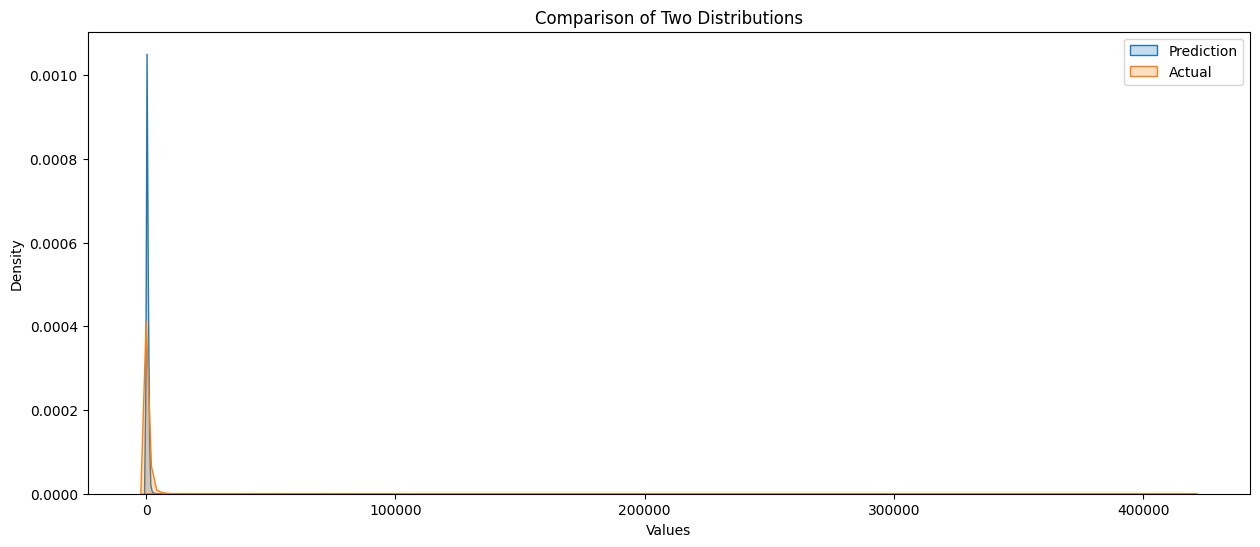

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'data1' and 'data2' are your two numerical datasets
plt.figure(figsize=(15, 6))  # Adjust the width and height as needed

# Plotting KDEs for both datasets on the same plot
sns.kdeplot(data=tot_pred, shade=True, label='Prediction')
sns.kdeplot(data=val_targets, shade=True, label='Actual')

plt.title('Comparison of Two Distributions')
plt.xlabel('Values')
plt.ylabel('Density')
plt.legend()  # Show legend indicating the distributions
plt.show()


In [ ]:
print(f'mean_actual = {np.array(val_targets).mean()}, mean_predicted = {np.array(tot_pred).mean()}')
print(f'std_actual = {np.array(val_targets).std()}, std_predicted = {np.array(tot_pred).std()}')

mean_actual = 777.0876243318222, mean_predicted = 451.8295402716248
std_actual = 5226.573464927433, std_predicted = 1817.2694900278987


In [ ]:
from sklearn.metrics import mean_squared_error

array1 = np.array(val_targets)  # Replace with your first array
array2 = np.array(tot_pred)  # Replace with your second array

rmse = np.sqrt(mean_squared_error(array1, array2))

print("RMSE:", rmse)

RMSE: 5145.211249204561


In [42]:
torch.save(model.state_dict(), 'desai2.pth')

TESTING COMPANY

In [ ]:
'''test_df_image_comp = pd.read_csv('csv_test_data/test_image_embeddings[comp].csv').drop(['Unnamed: 0'],axis=1)
test_df_comp_comp = pd.read_csv('csv_test_data/test_company_enc_red_comp.csv')
test_df_text_comp = pd.read_csv('csv_test_data/test_text_enc_red_comp.csv')
test_df_rest_comp = pd.concat([test_df_comp_comp,test_df_text_comp],axis=1)
print(test_df_rest_comp.shape)
test_df_errors_comp = pd.read_csv('csv_test_data/test_image_embeddings_errors[comp].csv')
to_be_deleted = list(test_df_errors_comp['0'])
test_df_rest_comp.drop(to_be_deleted,inplace=True)
test_df_rest_comp.reset_index(drop=True,inplace=True)
test_df_rest_temp_comp = test_df_rest_comp.dropna(axis=1, how='any')
test_df_rest_temp_comp.shape'''

(10000, 64)


(9914, 64)

In [ ]:
'''df_final_comp = pd.concat([test_df_rest_temp_comp,test_df_image_comp],axis=1)
df_final_comp.shape'''

(9914, 576)

In [ ]:
'''temp = pd.DataFrame(np.zeros(9914))
test_dataset_comp = TabularDataset(df_final_comp,temp)
test_loader_comp = DataLoader(test_dataset_comp,
                        batch_size=batch_size,
                        shuffle=False)'''

torch.Size([9914, 576])
torch.Size([9914, 1])


In [ ]:
'''tot_pred_comp = []
with torch.no_grad():
        model.eval()

        for (x, y) in test_loader_comp:
            (x, y) = (x.to(device), y.to(device))
            pred = model(x).reshape(-1)
            tot_pred_comp.extend(pred.tolist())

len(tot_pred_comp)'''

9914

In [ ]:
'''mean_comp = np.array(tot_pred_comp).mean()
mean_comp'''

515.0223680524689

In [ ]:
'''array1 =[0]*10000
j = 0
for i in range(10000):
    if i in to_be_deleted:
        array1[i] = mean_comp
    else:
        if tot_pred_comp[j]<0:
            array1[i]=0
        else:
            array1[i] = tot_pred_comp[j]
        j=j+1
len(array1)'''

NameError: name 'tot_pred_comp' is not defined

In [ ]:
'''df0 = pd.DataFrame(array1)

# Save the DataFrame to an Excel file
df0.to_excel('behaviour_simulation_test_company.xlsx', index=False)  # Save to an Excel file named 'output.xlsx' without index'''

TESTING TIME

In [ ]:
'''test_df_image_time = pd.read_csv('csv_test_data/test_image_embeddings[time].csv').drop(['Unnamed: 0'],axis=1)
test_df_comp_time = pd.read_csv('csv_test_data/test_company_enc_red_time.csv')
test_df_text_time = pd.read_csv('csv_test_data/test_text_enc_red_time.csv')
test_df_rest_time = pd.concat([test_df_comp_time,test_df_text_time],axis=1)
print(test_df_rest_time.shape)
test_df_errors_time = pd.read_csv('csv_test_data/test_image_embeddings_errors[time].csv')
to_be_deleted = list(test_df_errors_time['0'])
test_df_rest_time.drop(to_be_deleted,inplace=True)
test_df_rest_time.reset_index(drop=True,inplace=True)
test_df_rest_temp_time = test_df_rest_time.dropna(axis=1, how='any')
test_df_rest_temp_time.shape'''

(10000, 64)


(9881, 64)

In [ ]:
'''df_final_time = pd.concat([test_df_rest_temp_time,test_df_image_time],axis=1)
df_final_time.shape'''

(9881, 576)

In [ ]:
'''temp = pd.DataFrame(np.zeros(9881))
test_dataset_time = TabularDataset(df_final_time,temp)
test_loader_time = DataLoader(test_dataset_time,
                        batch_size=batch_size,
                        shuffle=False)'''

torch.Size([9881, 576])
torch.Size([9881, 1])


In [ ]:
'''tot_pred_time = []
with torch.no_grad():
        model.eval()

        for (x, y) in test_loader_time:
            (x, y) = (x.to(device), y.to(device))
            pred = model(x).reshape(-1)
            tot_pred_time.extend(pred.tolist())

len(tot_pred_time)'''

9881

In [ ]:
'''mean_time = np.array(tot_pred_time).mean()
mean_time'''

445.90695565051607

In [ ]:
'''array2 =[0]*10000
j = 0
for i in range(10000):
    if i in to_be_deleted:
        array2[i] = mean_time
    else:
        if tot_pred_time[j]<0:
            array2[i]=0
        else:
            array2[i] = tot_pred_time[j]
        j=j+1
len(array2)'''

10000

In [ ]:
'''df00 = pd.DataFrame(array2)

# Save the DataFrame to an Excel file
df00.to_excel('behaviour_simulation_test_time.xlsx', index=False)  # Save to an Excel file named 'output.xlsx' without index'''